### Phase 1: Cointegration Screening

Two assets are cointegrated if some fixed combination of them stays in a stable range, even though each one individually wanders. That stable combination is the spread, and it is what a pairs trade actually bets on. This notebook looks for pairs like that.

The standard tool is the Engle-Granger (EG) test. EG assumes the hedge ratio β is one fixed number for the whole sample. That assumption is the problem. If the true β drifts over time, EG is looking for something that isn't there (a single constant relationship) and it can come back negative even when a real, time-varying relationship exists. This is called low power, where the test fails to find what is actually present.

So a failed EG test is ambiguous. It can mean either:

- there is no relationship between the two assets, or
- there is a relationship, but β moves, and a constant-β test can't see it.

This notebook sets up the question honestly: screen a 20-pair universe across five time windows, document where static EG succeeds and fails, and produce the rolling evidence that later notebooks test with state-space methods. If those methods also fail, the answer is (a), and that's still a real result that can be built upon.

All pricing runs on log prices. Differences of log prices are (approximately) returns, which makes β a portfolio weight, how many dollars of X per dollar of Y, instead of a share count. That matters later when the spread gets traded.

### Cell 1: Imports

- `numpy`, `pandas` — arrays and date-aligned time series
- `yfinance` — price data
- `matplotlib` — plots
- `statsmodels` — OLS, the ADF unit root test, and the Engle-Granger cointegration test

yfinance pulls free retail data from Yahoo Finance. Known issues: corporate actions are sometimes handled inconsistently, history can be silently revised, no guarantee of accuracy. It's good enough for a screening study where the conclusion is a null result, but any pair that looked tradeable here would need to be re-checked against a real vendor before anyone believed it.

`ADF_MAXLAG` is also defined here rather than lower down, because it is a study-wide parameter fixed in advance and every test in this notebook uses the same value. See Cell 4 for why it is set to 1.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("..")) 
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
import warnings
from statsmodels.tools.sm_exceptions import CollinearityWarning
# Expected for the degenerate control pairs (GLD/IAU, SPY/IVV); they are flagged explicitly in Cell 4
warnings.filterwarnings("ignore", category=CollinearityWarning)
ADF_MAXLAG = 1

### Cell 2: Building the Price Panel

The 20 pairs contain 39 unique tickers (GLD twice). This cell pulls 10 years of adjusted closes for each and combines them into one DataFrame. The work happens in `models/data.py` so that this notebook and `02_ols_benchmarks.ipynb` are to run on the same data.

Adjusted closes - `auto_adjust=True` rolls dividends and splits into the price. Without it, a 2-for-1 split looks like the stock lost half its value overnight, which would wreck every regression here. We set it explicitly rather than trusting the library default.

Timezone stripping - yfinance returns timestamps that carry a timezone. Two tickers can tag the same trading day with different offsets, and pandas treats those as two different dates. It then creates two rows, each half-empty, and `dropna()` deletes both. `tz_localize(None).normalize()` forces everything onto a plain calendar date so the alignment works.

One panel - Every pair is sliced out of the same DataFrame, so every pair is tested on the exact same set of dates. `dropna()` keeps only days where all 39 tickers traded. That is an inner join, so one late-listing ticker could shorten the sample for everyone. We print the first available date per ticker to see exactly who is binding. Right now nothing is: all 39 tickers start on the same date and no rows are lost.

Pinning the dataset - `load_panel()` in `models/data.py` caches the price panel to `data/prices.parquet` at the repo root. Notebook 02 reads that same file instead of downloading again. Two separate downloads on two different days would give two different datasets, and the p-values in this notebook would no longer describe the same universe as the backtest in 02. To refresh the data, delete the parquet file and re-run this cell.

Then `log_prices = np.log(prices)`, which is what everything downstream actually tests.

The plot at the end is a visual on GLD and SLV, both divided by their first value so they start at 1.0 and can be compared on a percentage basis. It is orientation, not evidence.

Earliest available date per ticker:
AAPL   2016-07-22
V      2016-07-22
MSFT   2016-07-22
PEP    2016-07-22
QQQ    2016-07-22 

Panel: 2512 rows x 39 tickers
Span:  2016-07-22 → 2026-07-21


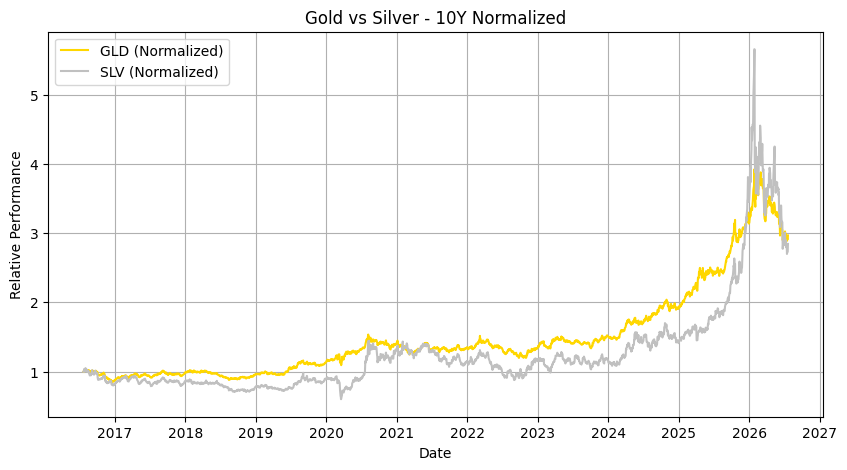

In [2]:
from models.data import PAIRS, load_panel

prices, log_prices = load_panel()
coverage = prices.apply(lambda c: c.first_valid_index())

print("Earliest available date per ticker:")
print(coverage.sort_values(ascending=False).head(5).to_string(), "\n")
print(f"Panel: {log_prices.shape[0]} rows x {log_prices.shape[1]} tickers")
print(f"Span:  {log_prices.index[0].date()} → {log_prices.index[-1].date()}")

# Normalize the prices for better visual 
gold_normalized = prices['GLD'] / prices['GLD'].iloc[0]
silver_normalized = prices['SLV'] / prices['SLV'].iloc[0]

# Plot them cleanly using the Pandas index automatically
plt.figure(figsize=(10, 5)) # Makes the chart wider and easier to see
plt.plot(prices.index, gold_normalized, label="GLD (Normalized)", color="gold")
plt.plot(prices.index, silver_normalized, label="SLV (Normalized)", color="silver")

plt.title("Gold vs Silver - 10Y Normalized")
plt.xlabel("Date")
plt.ylabel("Relative Performance")
plt.legend() 
plt.grid(True) 
plt.show()

### Cell 3: Single-Asset Unit Root Check

Before testing pairs, check that a single series behaves the way cointegration theory requires.

Cointegration is a claim about two series that are each individually non-stationary but whose combination is stationary. So the setup only makes sense if the individual log prices are non-stationary to begin with. If GLD's log price were already mean-reverting on its own, you wouldn't need a pair at all.

The Augmented Dickey-Fuller (ADF) test checks this. Its null hypothesis is "this series has a unit root," (it wanders). A high p-value means we fail to reject that, which is the goal in this case.

ADF runs a regression that includes some number of lagged differences. Those lag terms exist to soak up short-run serial correlation so the coefficient we actually care about is clean. Choosing how many is important, and the usual default (`autolag='AIC'`) turned out to be harmful in this project (See Cell 4). We use a fixed `maxlag=ADF_MAXLAG` with `autolag=None` here so that this diagnostic uses the same rule as the rest of the notebook.

`autolag=None` means "don't search, use `maxlag`." Leaving `maxlag` unset makes statsmodels substitute a large default. Both parameters have to be set together.

In [3]:
# Running ADF on Gold to find test_statistic, p-value, and whether it's stationary

adf = adfuller(
    log_prices["GLD"],
    maxlag=ADF_MAXLAG,
    regression='c',
    autolag=None)

test_statistic, p_value = adf[0], adf[1]
stationary = p_value < 0.05
print(f"ADF t={test_statistic:.4f}  p={p_value:.4f}  stationary={stationary}")

ADF t=0.5635  p=0.9867  stationary=False


# Cell 4: Cointegration Scanner

This cell tests all 20 pairs across five windows (1Y, 2Y, 3Y, 5Y, 10Y) and reports p-values, half-lives, and verdicts.

---

### 1. What `engle_granger` does

Step 1 — Degeneracy flag. Compute correlation of daily returns. If r > 0.99, the two assets are essentially the same thing (GLD/IAU both hold gold). Flag it and run. The label is a conclusion we attach afterward. Note this is computed on returns: correlation between two trending series is high by construction and tells you nothing.

Step 2 — I(1) filter. Both log price series must be non-stationary in levels, and both must become stationary after one difference (Integrated of Order 1). It's the precondition for cointegration to be a coherent question. If a pair fails, we return a string saying exactly which of the four conditions broke.

Step 3 — Engle-Granger on both directions. Regress Y on X, and X on Y, and keep the smaller p-value. EG is not symmetric, meaning which asset you put on the left side changes the answer — there is no principled way to pick in advance for most of these pairs. Taking the minimum of two tests is itself a multiple comparison, so the real number of tests at the 5Y window is 40, not 20, and the Bonferroni denominator has to reflect that.

Step 4 — Half-life. Fit the spread to an AR(1) and convert to a half-life in days (see below). This is a tradeability measure. A spread that reverts in 500 days is not something you can trade even if it is technically cointegrated.

Step 5 — Verdict. Only the 5Y window produces a verdict. Everything else is labeled `exploratory`.

---

### 2. Multiple testing

We test 20 pairs × 5 windows × 2 directions. Running that many tests at a 5% threshold guarantees false positives - roughly 1 in 20 tests comes back "significant" from luck alone.

The 5Y window is the confirmatory test, at α = 0.05 / (2 × 20) = 0.00125. The other four windows are exploratory. They are printed, but they do not produce verdicts and no claim rests on them. Their job is to show how p-values and β move as the window changes which is evidence about parameter instability.

This distinction is the defense against only using passing tests from the over 200 ran.

---

### 3. The math

All inputs are log prices in spread calculations:

$$\text{Spread}_t = Y_t - \beta X_t - \alpha$$

Half-life - The Ornstein-Uhlenbeck process is the continuous-time version of mean reversion:

$$ds_t = \theta(\mu - s_t)\,dt + \sigma\,dW_t$$

Converting it to a discrete series results in an AR(1):

$$\Delta s_t = c + \gamma s_{t-1} + \varepsilon_t$$

where $\gamma = -\theta$ and $c = \theta\mu$. So `params.iloc[1]` is $-\theta$ and must be negative for the spread to revert at all. If it is positive the spread is running away, and we return infinity rather than take the log of a non-positive number. Half-life is then:

$$t_{1/2} = \frac{-\ln 2}{\ln(1 + \gamma)}$$

which results in the number of days it takes for the spread to decay halfway back when there is a shock.

---

### 4. Lag order

ADF includes lagged differences to absorb short-run serial correlation. The library default picks the number automatically by minimizing AIC. 

The problem is that AIC over-fits with positive probability no matter how much data you have. On a residual that is mostly short-lived noise, ADF will happily chase that noise into double-digit lag counts. When it does, the lagged difference terms absorb the mean reversion that the level coefficient is supposed to be testing for. The test explains the signal away and then reports it found nothing.

GLD and IAU both hold physical gold; their spread reverts within days. AIC selected 8 lags and returned p = 0.368 — no cointegration between two funds holding the same metal. At maxlag = 1 the same test returns p = 0.0007. So `ADF_MAXLAG = 1`, fixed in advance, applied identically to every pair, window, and test in this notebook.

Appendix A reports the full sweep so the null result can be checked against every reasonable lag choice, not just ours.

In [4]:
BONF_ALPHA = 0.05 / (2 * len(PAIRS))

def check_stationarity(series):
    p = adfuller(series, maxlag=ADF_MAXLAG, regression='c', autolag=None)[1]
    return p < 0.05

def half_life(spread):
    d = spread.diff()
    lag = spread.shift(1)
    combo = pd.concat([d, lag], axis=1).dropna()
    combo.columns = ["d", "lag"]
    fit = sm.OLS(combo["d"], sm.add_constant(combo["lag"])).fit()
    gamma = fit.params.iloc[1]
    if gamma >= 0:
        return np.inf
    return -np.log(2) / np.log(1 + gamma)

def engle_granger(lx, ly, alpha_thresh, confirmatory = False):
    # Degenerate flag
    r = lx.diff().corr(ly.diff())
    degenerate = r > 0.99

    i0 = check_stationarity(lx); i1 = check_stationarity(ly)
    d0 = check_stationarity(lx.diff().dropna()); d1 = check_stationarity(ly.diff().dropna())
    if not ((not i0) and (not i1) and d0 and d1):
        reason = []
        if i0: reason.append("X stationary in levels")
        if i1: reason.append("Y stationary in levels")
        if not d0: reason.append("X diff non-stationary")
        if not d1: reason.append("Y diff non-stationary")
        return {"verdict": "Not I(1): " + "; ".join(reason),
                "p": np.nan, "dep": None, "hl": np.nan, "degen": degenerate}

    p_a = coint(ly, lx, trend='c', autolag=None, maxlag=ADF_MAXLAG)[1]
    p_b = coint(lx, ly, trend='c', autolag=None, maxlag=ADF_MAXLAG)[1]
    if p_a <= p_b:
        p_win, Y, X, dep = p_a, ly, lx, "B~A"
    else:
        p_win, Y, X, dep = p_b, lx, ly, "A~B"

    fit = sm.OLS(Y, sm.add_constant(X)).fit()
    a_, b_ = fit.params.iloc[0], fit.params.iloc[1]
    spread = Y - b_ * X - a_
    hl = half_life(spread)

    if confirmatory:
        verdict = "Cointegrated" if p_win < alpha_thresh else "Not Cointegrated"
    else:
        verdict = "exploratory"
    if degenerate:
        verdict += " (Degenerate)"
    return {"verdict": verdict, "p": p_win, "dep": dep, "hl": hl, "degen": degenerate}

windows = {252: "1Y", 504: "2Y", 756: "3Y", 1260: "5Y", None: "10Y"}

rows = []
for days, label in windows.items():
    sl = log_prices if days is None else log_prices.iloc[-days:]
    for a, b in PAIRS:
        res = engle_granger(sl[a], sl[b], BONF_ALPHA, confirmatory=(label == "5Y"))
        rows.append({"window": label, "pair": f"{a}/{b}",
                     "p": res["p"], "half_life": res["hl"],
                     "dep": res["dep"], "verdict": res["verdict"]})

results = pd.DataFrame(rows)
table1 = results.pivot(index="pair", columns="window", values="p")[["1Y","2Y","3Y","5Y","10Y"]]
print("\n" + results[results.window == "5Y"][["pair", "p", "half_life", "verdict"]]
      .round(4).to_string(index=False))
print(f"Bonferroni ⍺= {BONF_ALPHA:.4f}  |   window = 5Y\n")
print(table1.round(4).to_string())


     pair      p  half_life                       verdict
  GLD/SLV 0.1788    64.1872              Not Cointegrated
  GLD/IAU 0.0005     8.1830     Cointegrated (Degenerate)
  SPY/IVV 0.0000     0.6024     Cointegrated (Degenerate)
  XLE/XOP 0.0667    39.9794              Not Cointegrated
  EEM/EMB 0.2502    51.3888              Not Cointegrated
   KO/PEP 0.1273    49.4581              Not Cointegrated
  XOM/CVX 0.1713    67.2920              Not Cointegrated
   HD/LOW 0.1122    45.0091              Not Cointegrated
     V/MA 0.0365    34.8993              Not Cointegrated
  EWA/EWC 0.0402    32.9491              Not Cointegrated
  USO/BNO 0.0144    43.2659              Not Cointegrated
  TLT/IEF 0.9416   500.3054              Not Cointegrated
  XLK/QQQ 0.5346   114.2294              Not Cointegrated
 GDX/GDXJ 0.0737    49.1189              Not Cointegrated
  XLP/XLU 0.0448    38.0541              Not Cointegrated
  IWM/IWO 0.2262    70.7408              Not Cointegrated
  EFA/VEA 0.8

### Cell 5: Pipeline Validation Gate

Before believing any result in this notebook, check that the scanner can find cointegration when cointegration is definitely there.

GLD and IAU are both physically-backed gold ETFs holding the same metal. SPY and IVV both track the S&P 500. These pairs are cointegrated by construction. Their log prices differ by roughly a constant. If the scanner cannot detect that, it is broken, and every "Not Cointegrated" verdict elsewhere in the table is noise rather than evidence.

Pass conditions:

1. `p < 0.01` — the test detects the relationship
2. `0.90 < β < 1.10` — on log prices β is an elasticity, so a 1% move in one should produce roughly a 1% move in the other. A β far from 1 would mean the regression is picking up a scale artifact instead of a hedge ratio.

Either one failing means the gate failed. R² should be about 0.9999 — but it is deliberately not a pass condition. R² is near 1 for these pairs no matter what, so including it would make the gate impossible to fail, which would make it useless.

The check ends in `assert`. If it fails, the notebook stops.

#####Note -
This gate failed the first time it ran (GLD/IAU p = 0.368, SPY/IVV p = 0.112), which is how the AIC lag-selection bug in Cell 4 was found.


In [5]:
# Testing pairs that are the "same" to watch for degenerate pairs
GATE_PAIRS = [("GLD", "IAU"), ("SPY", "IVV")]
sl_5y = log_prices.iloc[-1260:]

gate_passed = True
for a, b in GATE_PAIRS:
    lx, ly = sl_5y[a], sl_5y[b]
    p = coint(ly, lx, trend='c', autolag=None, maxlag=ADF_MAXLAG)[1]
    fit = sm.OLS(ly, sm.add_constant(lx)).fit()
    beta = fit.params.iloc[1]
    r2 = fit.rsquared

    ok = (p < 0.01) and (0.90 < beta < 1.10)
    gate_passed &= ok
    print(f"{a}/{b:5s} p={p:.6f}  beta={beta:.4f}  R2={r2:.6f}  {'PASS' if ok else 'FAIL'}")

assert gate_passed, (
    "VALIDATION GATE FAILED. The scanner cannot detect cointegration "
    "between assets that are cointegrated by construction. Do not proceed."
)
print("\nGate passed — scanner validated.")

GLD/IAU   p=0.000493  beta=1.0059  R2=0.999993  PASS
SPY/IVV   p=0.000000  beta=1.0044  R2=0.999997  PASS

Gate passed — scanner validated.


### Cell 6: Rolling Engle-Granger

Static EG forces one β across the entire sample. If the true hedge ratio moves, that assumption is wrong and the test loses power.

The approach is to slide a 2-year window across the sample, re-running EG and re-estimating β inside each window. Two years is short enough that β is roughly constant within a window, but long enough for the test to have some power. We step forward 5 days at a time; performing daily cost calculations 80% less.

For date bookmarking The slice `[end - window : end]` is half-open. It includes position `end - window` through `end - 1`. The last observation in the window is at `end - 1`, not `end`. So we take the date  off the slice with `sx.index[-1]` rather than computing it separately. Doing arithmetic on the position index and the date index independently would lead to lookahead bias — the model using information it could not have had.

Prediction:

- If hypothesis (b) holds, p should dip low during stretches where β is stable and spike where β is drifting. 
- If hypothesis (a) holds, p stays uniformly high and nothing lines up.

The two panels share an x-axis for exactly this reason. The claim is that p is low when β is stable, and that is only visible with the two aligned.

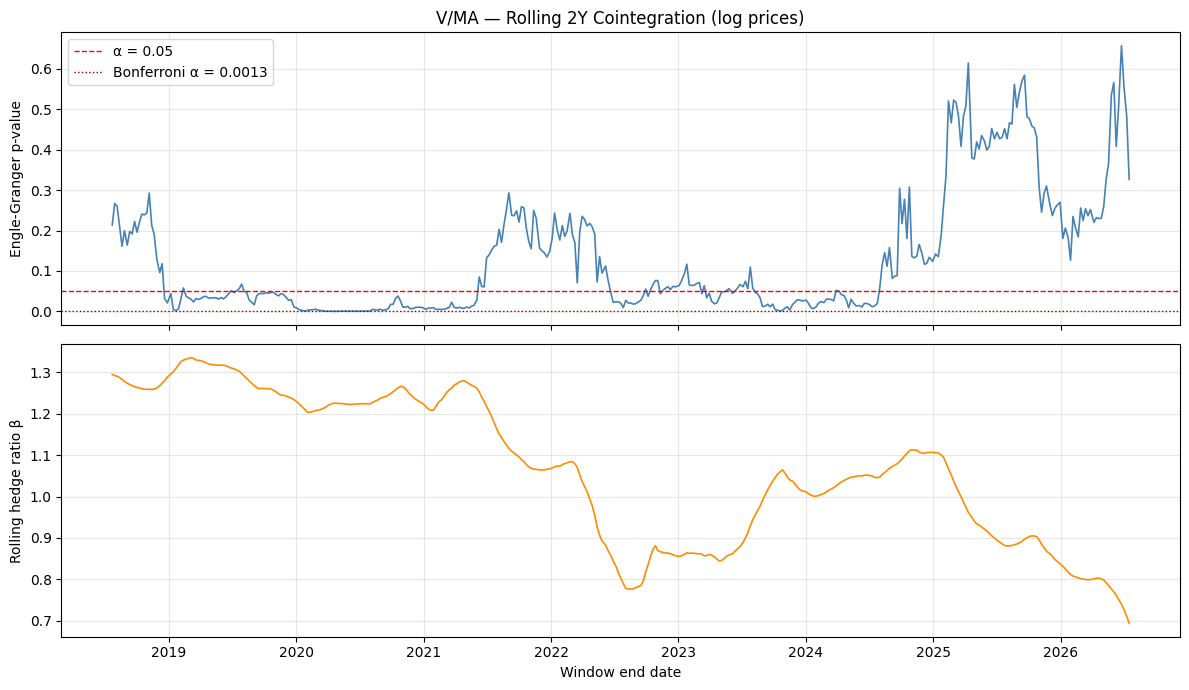

Fraction of windows cointegrated at 5%: 47.8%
Beta range: 0.694 → 1.335
Beta std:   0.175


In [6]:
def rolling_engle_granger(lx, ly, window=504, step=5):
    records = []
    for end in range(window, len(lx) + 1, step):
        sx = lx.iloc[end - window:end]
        sy = ly.iloc[end - window:end]

        p = coint(sy, sx, trend='c', autolag=None, maxlag=ADF_MAXLAG)[1]
        fit = sm.OLS(sy, sm.add_constant(sx)).fit()

        records.append({
            "date":  sx.index[-1],
            "p":     p,
            "beta":  fit.params.iloc[1],
            "alpha": fit.params.iloc[0],
        })
    return pd.DataFrame(records).set_index("date")

PAIR = ("V", "MA")
roll = rolling_engle_granger(log_prices[PAIR[0]], log_prices[PAIR[1]], window=504, step=5)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax1.plot(roll.index, roll["p"], color="steelblue", lw=1.2)
ax1.axhline(0.05, color="red", ls="--", lw=1, label="α = 0.05")
ax1.axhline(BONF_ALPHA, color="darkred", ls=":", lw=1, label=f"Bonferroni α = {BONF_ALPHA:.4f}")
ax1.set_ylabel("Engle-Granger p-value")
ax1.set_title(f"{PAIR[0]}/{PAIR[1]} — Rolling 2Y Cointegration (log prices)")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(roll.index, roll["beta"], color="darkorange", lw=1.2)
ax2.set_ylabel("Rolling hedge ratio β")
ax2.set_xlabel("Window end date")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

frac = (roll["p"] < 0.05).mean()
print(f"Fraction of windows cointegrated at 5%: {frac:.1%}")
print(f"Beta range: {roll['beta'].min():.3f} → {roll['beta'].max():.3f}")
print(f"Beta std:   {roll['beta'].std():.3f}")

### Cell 7: Beta Volatility vs p-value Alignment

When running a rolling EG test, we generate two continuous time series - the rolling p-value (strength of cointegration relationship) and the rolling hedge ratio (the dollar relationship between the two assets). When looking at the relationship between those two time series a question is raised: at a given time when the p-value is low, is the hedge ratio stable?

To test this we will calculate the $b_{ratio}$ between the time series which is ratio of the median of the rolling beta volatility when $p < 0.05$ and median of beta volatility across the entire sample. If $b_{ratio}$ is clearly less than one (~0.3), it is stable and if $b_{ratio}$ is closer to one (~0.8), there is a mild alignment between the two series.

In [7]:
b_volatility = roll["beta"].rolling(window=20, center=True, min_periods=10).std()
is_coint = roll["p"] < 0.05

b_volatility_sub5 = b_volatility[is_coint]

median_sub5 = b_volatility_sub5.median()
median_total = b_volatility.median()

b_ratio = median_sub5 / median_total

print(f"--- Alignment Diagnostics (bratio) ---")
print(f"Median β-volatility (p < 0.05) : {median_sub5:.6f}")
print(f"Median β-volatility (Overall)  : {median_total:.6f}")
print(f"bratio (sub-0.05 / overall)    : {b_ratio:.4f}")

--- Alignment Diagnostics (bratio) ---
Median β-volatility (p < 0.05) : 0.017403
Median β-volatility (Overall)  : 0.019720
bratio (sub-0.05 / overall)    : 0.8825


### Cell 8: Static-power Exhibit

As demonstrated in Exhibit 1.1 below, full-sample static cointegration tests suffer from low statistical power due to parameter drift. When testing many pairs - in our case 20, where the Bonferroni correction drops the cointegration threshold to 0.00125 - static EG discards relationship such as V and MA as statistical noise. However, a dynamic rolling lens reveals the pair cointegrated in 47.8% of rolling windows, including a continuous run of 93 windows (~465 trading days, at a 5-day step).

Filtering universe pairs via static p-value gates is insufficient for regime-switching market assets. In 02_ols_benchmarks.ipynb, we establish static and rolling OLS baselines to quantify the performance drag and lag associated with window-based parameter estimation before introducing real-time state-space filtering in 03_kalman_filter.ipynb.

In [8]:
_pa = coint(sl_5y["MA"], sl_5y["V"], trend='c', autolag=None, maxlag=ADF_MAXLAG)[1]
_pb = coint(sl_5y["V"], sl_5y["MA"], trend='c', autolag=None, maxlag=ADF_MAXLAG)[1]
static_p_vma = min(_pa, _pb)

_below = (roll["p"] < 0.05).astype(int).values
_run = _max = 0
for _v in _below:
    _run = _run + 1 if _v else 0
    _max = max(_max, _run)
longest_run = _max

frac = (roll["p"] < 0.05).mean()

print(f"static V/MA 5Y p = {static_p_vma:.4f}")
print(f"Bonferroni bar   = {BONF_ALPHA:.5f}")
print(f"rolling frac     = {frac:.1%}")
print(f"longest run      = {longest_run} windows")

exhibit_df = pd.DataFrame({
    "Diagnostic Lens": [
        "Static Full-Sample (5Y)",
        "Bonferroni Multiple-Testing Gate",
        "Dynamic Rolling Lens (2Y window)",
    ],
    "Statistical Metric": [
        "Engle-Granger p-value (min of both directions)",
        "Bonferroni threshold (α = 0.05 / 40)",
        "Sub-0.05 fraction / longest continuous run",
    ],
    "Value": [
        f"{static_p_vma:.4f}",
        f"{BONF_ALPHA:.5f}",
        f"{frac:.1%} / {longest_run} windows",
    ],
    "Interpretation": [
        "Significant under a naive α = 0.05 cutoff.",
        "Static relationship not distinguishable from noise under multiple-testing correction.",
        "Reveals a persistent multi-year continuous cointegrated regime the static test misses.",
    ],
})

exhibit_df

static V/MA 5Y p = 0.0365
Bonferroni bar   = 0.00125
rolling frac     = 47.8%
longest run      = 93 windows


,Diagnostic Lens,Statistical Metric,Value,Interpretation
0,Static Full-Sample (5Y),Engle-Granger p-value (min of both directions),0.0365,Significant under a naive α = 0.05 cutoff.
1,Bonferroni Multiple-Testing Gate,Bonferroni threshold (α = 0.05 / 40),0.00125,Static relationship not distinguishable from n...
2,Dynamic Rolling Lens (2Y window),Sub-0.05 fraction / longest continuous run,47.8% / 93 windows,Reveals a persistent multi-year continuous coi...


### Pre-Registration Notes
Date: July 21, 2026
Primary Test Pair: Visa / Mastercard (V/MA)
Secondary Robustness Pair: Exxon Mobil / Chevron (XOM/CVX)

#### 1. Context
We found the V/MA pair during a rolling Engle-Granger scan across 20 equity pairs (40 total directional tests). A standard full-sample test misses it once you apply a Bonferroni correction (p = 0.0365 vs the 0.00125 cut-off), but looking through a rolling window reveals a solid 93-window cointegrated run, covering 47.8% of the timeline under p = 0.05.

#### 2. Confirmatory Out-of-Sample Protocol
To make sure we do not tweak parameters after the tests or fall into data-snooping traps, all testing in Phase 2 (OLS baselines) and Phase 3 (Kalman Filtering) will stick to these locked-in rules:

- Every model evaluation happens strictly on the isolated Phase 2/3 out-of-sample test split.

- Entry is locked at +/-2.0 standard deviations, exit is locked at -/+0.5 standard deviations, and transaction costs are set to 5 bps per entry/exit.

- We are comparing four fixed models against each other: Model 1 (Static Full-Sample OLS), Model 2 (Rolling Window OLS), Model 3 (Static State-Space Local Level), and Model 4 (Dynamic State-Space Kalman Filter).

### Appendix A: ADF Lag Sensitivity

Cell 4 fixes the ADF lag order at 1 instead of letting AIC choose. That is a judgment call, and a reviewer is entitled to ask whether the null result depends on it.

This sweep re-runs the 5Y confirmatory test at maxlag ∈ {0, 1, 2, 4, 8, 16} for all 20 pairs, using the same "both directions minimum" rule as the main scanner so the maxlag = 1 column reproduces the 5Y column of Table 1 exactly.

What to look for:

- Real pairs are lag-insensitive. Their spreads revert over 30–60 days, so a handful of extra lags barely moves the p-value. The null holds across every column.
- The degenerate control pairs are extremely lag-sensitive. Their spreads revert in under a day to about a week, so over-lagging destroys the test entirely. GLD/IAU runs from p = 0.0000 at lag 0 to p = 0.46 at lag 16.

In [9]:
sweep = []
for L in [0, 1, 2, 4, 8, 16]:
    for a, b in PAIRS:
        try:
            pa = coint(sl_5y[b], sl_5y[a], trend='c', autolag=None, maxlag=L)[1]
            pb = coint(sl_5y[a], sl_5y[b], trend='c', autolag=None, maxlag=L)[1]
            p = min(pa, pb)
        except Exception:
            p = np.nan
        sweep.append({"maxlag": L, "pair": f"{a}/{b}", "p": p})
print(pd.DataFrame(sweep).pivot(index="pair", columns="maxlag", values="p").round(4).to_string())

maxlag         0       1       2       4       8       16
pair                                                     
EEM/EMB    0.1680  0.2502  0.3125  0.3888  0.5783  0.6503
EFA/VEA    0.8570  0.8687  0.8842  0.8262  0.8874  0.8533
EWA/EWC    0.0216  0.0402  0.0500  0.0635  0.0378  0.0508
GDX/GDXJ   0.0574  0.0737  0.0925  0.0848  0.0755  0.1518
GLD/IAU    0.0000  0.0005  0.0244  0.1752  0.3924  0.4554
GLD/SLV    0.1809  0.1788  0.1508  0.2328  0.2522  0.2363
HD/LOW     0.0807  0.1122  0.1418  0.1067  0.0759  0.0258
IWM/IWO    0.1734  0.2262  0.2452  0.1805  0.1597  0.0750
KO/PEP     0.1005  0.1273  0.1634  0.1746  0.1711  0.1298
LQD/HYG    0.2294  0.2181  0.2317  0.1786  0.1889  0.1326
MSFT/AAPL  0.8586  0.7974  0.8280  0.8077  0.9236  0.8948
SPY/IVV    0.0000  0.0000  0.0000  0.0000  0.0000  0.0337
TLT/IEF    0.9426  0.9416  0.9491  0.9515  0.9581  0.9553
USO/BNO    0.0675  0.0144  0.0032  0.0015  0.0336  0.1043
V/MA       0.0415  0.0365  0.0804  0.0702  0.0917  0.0273
XLE/XOP    0.0